<a href="https://colab.research.google.com/github/soumensen411/Deep-Learning-Model/blob/main/CNN/Few-Shot%20%26%20Zero%20Shot%20Learning/few_zero_shot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image

In [52]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cpu


In [53]:
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Remove classification layer
model.fc = nn.Identity()

model = model.to(device)
model.eval()

print("Model loaded successfully!")


Model loaded successfully!


In [54]:

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [55]:

import torchvision
from torch.utils.data import DataLoader
from collections import defaultdict
import random

# Download CIFAR-10
train_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = ["cat", "dog", "horse"]

# CIFAR-10 class IDs
class_ids = {
    "cat": 3,
    "dog": 5,
    "deer": 4,
    "horse": 7
}

print("Dataset loaded!")


Dataset loaded!


In [56]:
random.seed(42)

support_images = defaultdict(list)

for image, label in train_data:
    for class_name, class_id in class_ids.items():
        if label == class_id and len(support_images[class_name]) < 2:
            support_images[class_name].append(image)

    # Only break when we have collected exactly 2 images for each target class
    if len(support_images) == len(class_ids) and all(len(v) == 2 for v in support_images.values()):
        break

print("Support images:")
for name, images in support_images.items():
    print(name, ":", len(images))

Support images:
deer : 2
horse : 2
cat : 2
dog : 2


In [57]:

def extract_features(images):
    batch = torch.stack(images).to(device)

    with torch.no_grad():
        features = model(batch)

    return features

# Extract support features
prototypes = {}

for class_name, images in support_images.items():

    features = extract_features(images)

    # Average features = class prototype
    prototypes[class_name] = features.mean(dim=0)

print("Class prototypes created!")


Class prototypes created!


# Predict a new image

Predicted: cat
Actual: cat
Distances: {'deer': 22.421890258789062, 'horse': 21.709131240844727, 'cat': 17.357479095458984, 'dog': 18.42148208618164}


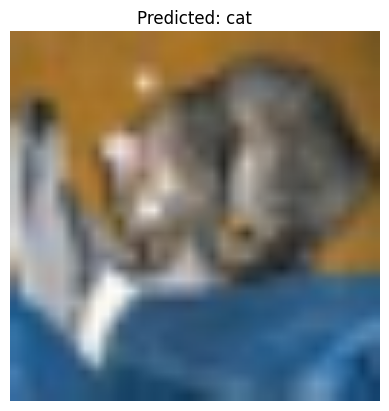

In [64]:
# Pick a query image belonging to our target classes (cat/dog/horse)
query_idx = next(i for i, t in enumerate(test_data.targets) if t in class_ids.values())
query_image, actual_label = test_data[query_idx]

query_feature = extract_features([query_image])[0]

distances = {}
for class_name, prototype in prototypes.items():
    distance = torch.norm(query_feature - prototype)
    distances[class_name] = distance.item()

prediction = min(distances, key=distances.get)
few_shot_prediction = prediction
print("Predicted:", prediction)
print("Actual:", train_data.classes[actual_label])
print("Distances:", distances)

# Revert ImageNet normalization values to make sure the image displays correctly
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
display_img = (query_image.cpu() * std + mean).clamp(0, 1)

plt.imshow(display_img.permute(1, 2, 0))
plt.title(f"Predicted: {prediction}")
plt.axis("off")
plt.show()

# Zero-Shot Learning Implementation

In [59]:

from transformers import CLIPProcessor, CLIPModel

clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

clip_model = clip_model.to(device)
clip_model.eval()

print("CLIP loaded successfully!")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded successfully!


In [60]:

text_prompts = [
    "A photo of a cat",
    "A photo of a dog",
    "A photo of a deer",
    "A photo of a horse"
]

Zero-Shot Prediction: A photo of a cat
Actual: cat
A photo of a cat : 59.98 %
A photo of a dog : 30.51 %
A photo of a deer : 4.18 %
A photo of a horse : 5.33 %


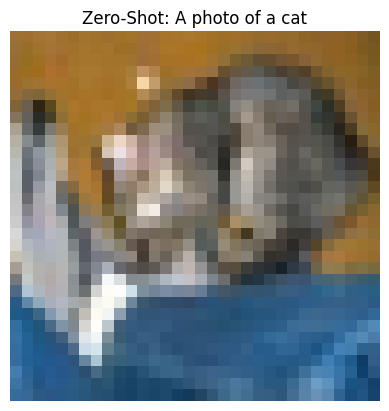

In [65]:
# Load the raw CIFAR-10 test set without transforms so we can get PIL images directly
raw_test_data = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True
)
query_image_pil, actual_label = raw_test_data[query_idx]

inputs = processor(
    text=text_prompts,
    images=query_image_pil,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = clip_model(**inputs)
    probabilities = outputs.logits_per_image.softmax(dim=1)

best_index = probabilities.argmax().item()
prediction = text_prompts[best_index]

print("Zero-Shot Prediction:", prediction)
print("Actual:", raw_test_data.classes[actual_label])

for text, score in zip(text_prompts, probabilities[0].tolist()):
    print(text, ":", round(score * 100, 2), "%")

# Display the original PIL image directly
plt.imshow(query_image_pil)
plt.title(f"Zero-Shot: {prediction}")
plt.axis("off")
plt.show()

In [63]:
actual = train_data.classes[actual_label]

zero_shot_prediction = prediction.replace(
    "A photo of a ", ""
)

print("========== RESULTS ==========")

print("Actual:", actual)

print("Few-Shot Prediction:", few_shot_prediction)
print("Zero-Shot Prediction:", zero_shot_prediction)

print("\nFew-Shot Correct:",
      few_shot_prediction == actual)

print("Zero-Shot Correct:",
      zero_shot_prediction == actual)

========== RESULTS ==========
Actual: cat
Few-Shot Prediction: cat
Zero-Shot Prediction: cat

Few-Shot Correct: True
Zero-Shot Correct: True
